# 06 · Simple linear regression

Linear regression describes how the conditional average of a response changes with a predictor. Fitting a line, measuring its training fit, testing a slope, and predicting a new observation are related but different tasks.

```mermaid
flowchart LR
    A[Scatterplot and model] --> B[Minimize squared residuals]
    B --> C[RSS, MSE, and R squared]
    C --> D[Slope t-test and overall F-test]
    D --> E[Mean and prediction intervals]
    E --> F[Diagnostics and scope]
```

**Learning route:** model → fit → evaluate → infer → predict → check. Prerequisites: Chapters 1–5; [AA](../AA_Prerequisite/AA_Prerequisite.md) derives least squares using calculus.

## 1. Separate the line from the observations

For package mass $x_i$ in kilograms and packing time $Y_i$ in minutes, a simple model is

$$Y_i=\beta_0+\beta_1x_i+\varepsilon_i,\qquad E[\varepsilon_i\mid x_i]=0.$$

Thus $E[Y_i\mid x_i]=\beta_0+\beta_1x_i$. The intercept $\beta_0$ is the mean response at $x=0$; the slope $\beta_1$ is the change in conditional mean per unit increase in $x$. Neither says every package follows the line exactly. The error $\varepsilon_i$ is the deviation from the unknown population line; a **residual** $e_i=y_i-\hat y_i$ is the deviation from the fitted line.

Predictor is clearer than “independent variable”: the label does not mean that observed predictor values are probabilistically independent, randomly assigned, or free from measurement error. The response is placed on the vertical axis because the model predicts it conditional on $x$.

## 2. Least squares chooses a line by its residuals

Ordinary least squares (OLS) minimizes

$$RSS(b_0,b_1)=\sum_i[y_i-(b_0+b_1x_i)]^2.$$

Residuals are **vertical** distances at the observed $x_i$, not shortest geometric distances to the line. Signed residuals could cancel; squared residuals cannot. Squaring also penalizes large errors more strongly than absolute-error loss.

With $S_{xx}=\sum_i(x_i-\bar x)^2>0$ and $S_{xy}=\sum_i(x_i-\bar x)(y_i-\bar y)$, the minimizing coefficients are

$$\hat\beta_1=\frac{S_{xy}}{S_{xx}},\qquad
\hat\beta_0=\bar y-\hat\beta_1\bar x.$$

The fitted line passes through $(\bar x,\bar y)$ and the residuals sum to zero when an intercept is included. If all $x_i$ are the same, $S_{xx}=0$: intercept and slope cannot be separately estimated. Two distinct predictor values can determine a line from two points, but then there are no residual degrees of freedom to estimate noise. Inference needs $n>2$ and a suitable design, not merely a line drawn through points.

## 3. A full calculation on five packages

Use invented observations $x=(1,2,3,4,5)$ kg and $y=(2,4,5,4,5)$ minutes. Then $\bar x=3$, $\bar y=4$, $S_{xx}=10$, and $S_{xy}=6$. Consequently,

$$\hat y=2.2+0.6x.$$

| $x$ | $y$ | $\hat y$ | Residual | Squared residual |
|---:|---:|---:|---:|---:|
| 1 | 2 | 2.8 | -0.8 | 0.64 |
| 2 | 4 | 3.4 | 0.6 | 0.36 |
| 3 | 5 | 4.0 | 1.0 | 1.00 |
| 4 | 4 | 4.6 | -0.6 | 0.36 |
| 5 | 5 | 5.2 | -0.2 | 0.04 |

The residual sum of squares is 2.4 minutes squared. The estimated slope is 0.6 additional minutes per kilogram. The intercept of 2.2 minutes concerns a hypothetical zero-mass package, outside the observed 1–5 kg range, so it may have little practical interpretation.

![Fitted line and vertical residuals](figure/least_squares.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '06_Linear_Regression' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


,mass_kg,time_min,fitted,residual,squared
0,1.0,2.0,2.8,-0.8,0.64
1,2.0,4.0,3.4,0.6,0.36
2,3.0,5.0,4.0,1.0,1.00
3,4.0,4.0,4.6,-0.6,0.36
4,5.0,5.0,5.2,-0.2,0.04


RSS=2.400, TSS=6.000, R-squared=0.600


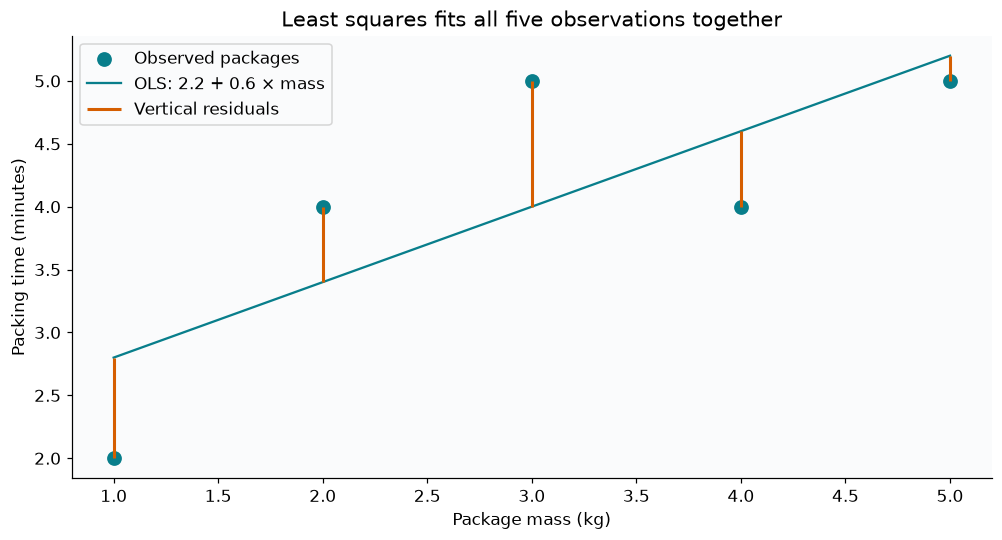

In [2]:
import statsmodels.api as sm
x = np.array([1,2,3,4,5],dtype=float)
y = np.array([2,4,5,4,5],dtype=float)
sxx = np.sum((x-x.mean())**2)
sxy = np.sum((x-x.mean())*(y-y.mean()))
slope = sxy/sxx
intercept = y.mean()-slope*x.mean()
fitted = intercept+slope*x
residuals = y-fitted
rss = np.sum(residuals**2)
tss = np.sum((y-y.mean())**2)
fit = sm.OLS(y,sm.add_constant(x)).fit()
assert np.allclose(fit.params,[2.2,.6]) and np.isclose(rss,2.4)
display(pd.DataFrame({"mass_kg":x,"time_min":y,"fitted":fitted,"residual":residuals,"squared":residuals**2}))
print(f"RSS={rss:.3f}, TSS={tss:.3f}, R-squared={1-rss/tss:.3f}")
fig, ax = plt.subplots(layout="constrained")
ax.scatter(x,y,s=75,label="Observed packages")
ax.plot(x,fitted,label="OLS: 2.2 + 0.6 × mass")
ax.vlines(x,fitted,y,color=ORANGE,lw=2,label="Vertical residuals")
ax.set(xlabel="Package mass (kg)",ylabel="Packing time (minutes)",title="Least squares fits all five observations together")
ax.legend()
save_figure(fig,"least_squares")

## 4. Measure fit with the right denominator

Define $TSS=\sum_i(y_i-\bar y)^2$. Here $TSS=6$. For OLS with an intercept and nonconstant response,

$$R^2=1-\frac{RSS}{TSS}=1-\frac{2.4}{6}=0.6.$$

The fitted model reduces training squared error by 60% relative to predicting the sample mean for every observation. This is not 60% prediction accuracy, a causal percentage, or a guarantee on new packages. In simple OLS with an intercept, this training $R^2$ equals squared sample Pearson correlation $r^2$. That identity is not a universal formula for arbitrary models.

Training **mean squared error** is $RSS/n=0.48$. Training **root mean squared error** is $\sqrt{RSS/n}\approx0.693$ minutes. The unbiased estimator of the error variance under the usual homoscedastic model is $\hat\sigma^2=RSS/(n-2)=0.8$, giving residual SD $\hat\sigma\approx0.894$ minutes. Some statistical software calls this last variance estimate “MSE”; always check which denominator is intended.

Training $R^2$ lies between zero and one for OLS with an intercept. On new data, $1-RSS_{\mathrm{test}}/TSS_{\mathrm{test}}$ can be negative: a fitted model can predict worse than the test-set mean benchmark. Without an intercept, even training conventions require care.

## 5. Test the slope and connect t to F

For classical exact inference, assume independent normal errors conditional on the predictors with mean zero and constant variance $\sigma^2$. Then

$$SE(\hat\beta_1)=\frac{\hat\sigma}{\sqrt{S_{xx}}},\qquad
t=\frac{\hat\beta_1-0}{SE(\hat\beta_1)}\sim t_{n-2}\quad\text{under }H_0:\beta_1=0.$$

Our estimated SE is $\sqrt{0.8/10}\approx0.28284$, so $t\approx2.1213$. With three degrees of freedom, the two-sided p-value is about 0.124. Five observations are insufficient for strong evidence here despite a training $R^2$ of 0.6.

Compare the reduced model, one common mean, with the full model, an intercept and slope:

$$F=\frac{(TSS-RSS)/1}{RSS/(n-2)}
=\frac{3.6}{0.8}=4.5.$$

Under the same assumptions, $F\sim F_{1,n-2}$ under the null, and $F=t^2$. The upper-tail F probability equals the two-sided t probability. The F-test uses an upper tail because squaring removes the sign: either a positive or negative slope can produce a large improvement. It does **not** test whether the optimized full model has larger training RSS than the reduced model; nested OLS prevents that increase.

In [3]:
df = len(x)-2
sigma_hat = np.sqrt(rss/df)
slope_se = sigma_hat/np.sqrt(sxx)
t_stat = slope/slope_se
f_stat = ((tss-rss)/1)/(rss/df)
p_t = 2*stats.t.sf(abs(t_stat),df)
p_f = stats.f.sf(f_stat,1,df)
assert np.isclose(f_stat,t_stat**2)
assert np.isclose(p_t,p_f) and np.isclose(p_t,fit.pvalues[1])
print(f"Slope SE={slope_se:.4f}; t={t_stat:.4f}; F={f_stat:.4f}; p={p_t:.4f}")
print("95% coefficient intervals:",fit.conf_int())

Slope SE=0.2828; t=2.1213; F=4.5000; p=0.1240
95% coefficient intervals: [[-0.78539926  5.18539926]
 [-0.30013175  1.50013175]]


## 6. Predict a mean or predict an individual?

At predictor value $x_*$, the estimated conditional mean is $\hat y_*=\hat\beta_0+\hat\beta_1x_*$. Its estimated SE is

$$SE_{\mathrm{mean}}=\hat\sigma\sqrt{\frac1n+\frac{(x_*-\bar x)^2}{S_{xx}}}.$$

A confidence interval for the conditional mean uses $\hat y_*\pm t^*SE_{\mathrm{mean}}$. A prediction interval for a **new independent observation** has an additional noise term:

$$\hat y_*\pm t^*\hat\sigma\sqrt{1+\frac1n+\frac{(x_*-\bar x)^2}{S_{xx}}}.$$

Both widen away from the observed predictor center; the prediction interval is wider because it includes individual variation. At $x_*=3$, our estimate is 4 minutes. The notebook calculates both intervals rather than confusing the mean's precision with individual predictability.

![Mean confidence band and individual prediction band](figure/prediction_intervals.png)

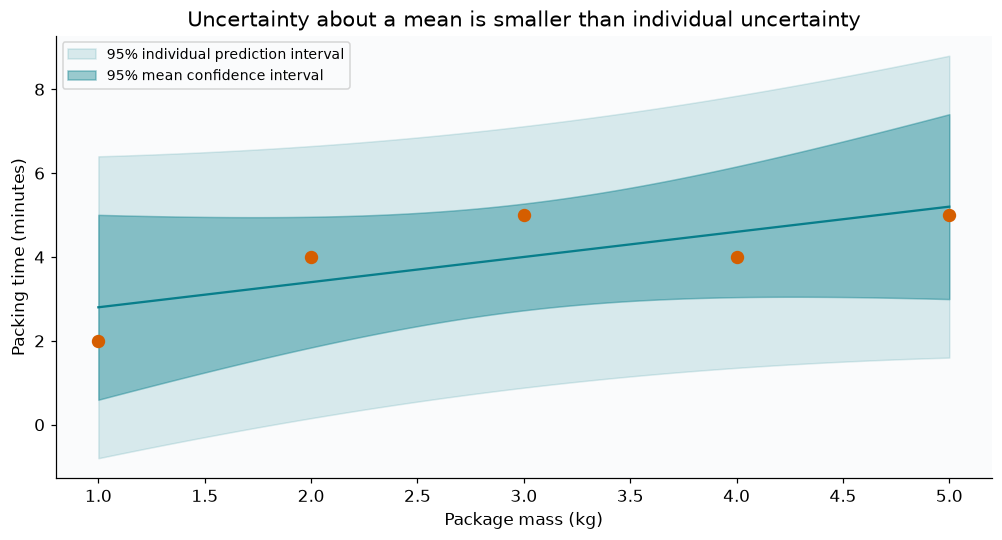

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,4.0,0.4,2.727021,5.272979,0.881852,7.118148


In [4]:
grid = np.linspace(1,5,120)
pred = fit.get_prediction(sm.add_constant(grid)).summary_frame(alpha=.05)
fig, ax = plt.subplots(layout="constrained")
ax.fill_between(grid,pred["obs_ci_lower"],pred["obs_ci_upper"],color=TEAL,alpha=.14,label="95% individual prediction interval")
ax.fill_between(grid,pred["mean_ci_lower"],pred["mean_ci_upper"],color=TEAL,alpha=.4,label="95% mean confidence interval")
ax.plot(grid,pred["mean"],color=TEAL)
ax.scatter(x,y,color=ORANGE,s=60)
ax.set(xlabel="Package mass (kg)",ylabel="Packing time (minutes)",title="Uncertainty about a mean is smaller than individual uncertainty")
ax.legend(fontsize=9)
save_figure(fig,"prediction_intervals")
display(fit.get_prediction(np.array([[1.,3.]])).summary_frame())

## 7. Check what a line may miss

A curved residual pattern suggests an inadequate mean function. A widening fan suggests nonconstant error variance. A plot in collection order can reveal dependence. A normal Q–Q plot can expose major tail departures relevant to small-sample classical inference. None of these plots proves assumptions; independence is primarily a design question.

![Residual patterns under suitable and unsuitable mean functions](figure/residual_patterns.png)

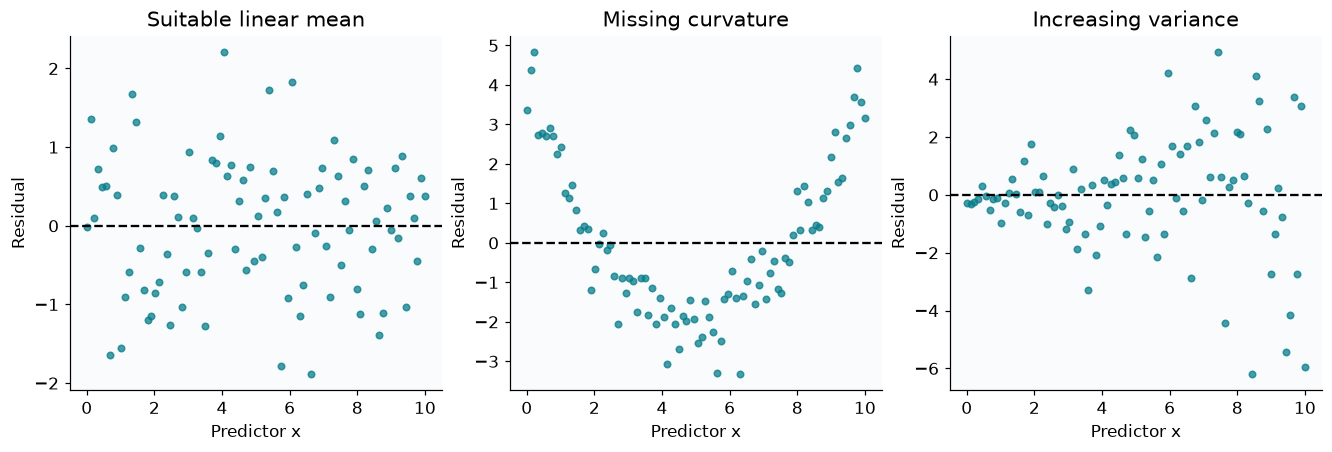

In [5]:
rng = np.random.default_rng(606)
dx = np.linspace(0,10,90)
fig, axes = plt.subplots(1,3,figsize=(12,4),layout="constrained")
examples = [
    ("Suitable linear mean",10+.5*dx+rng.normal(0,1,len(dx))),
    ("Missing curvature",10+.5*dx+.25*(dx-5)**2+rng.normal(0,.65,len(dx))),
    ("Increasing variance",10+.5*dx+rng.normal(0,.2+.3*dx,len(dx))),
]
for ax,(label,response) in zip(axes,examples):
    diagnostic_fit = sm.OLS(response,sm.add_constant(dx)).fit()
    ax.scatter(dx,diagnostic_fit.resid,s=18,alpha=.75)
    ax.axhline(0,color="black",ls="--")
    ax.set(xlabel="Predictor x",ylabel="Residual",title=label)
save_figure(fig,"residual_patterns")

Normality is not required to calculate OLS coefficients. Constant variance is not required for the line to minimize RSS. Those assumptions matter for particular variance formulas and exact tests. Heteroscedasticity-robust standard errors can address a variance-formula problem under appropriate conditions, but cannot fix confounding, severe dependence, or a wrong conditional mean.

An unusual predictor value has **leverage**; an observation that substantially changes the fit has **influence**. Verify data-entry errors and investigate influential observations rather than deleting valid inconvenient data. Record and justify any exclusions. Extrapolation beyond the observed $x$ range adds model risk that a narrow mathematical interval may not capture.

## 8. Practice

1. For $x=(0,1,2)$ and $y=(1,2,2)$, calculate the fitted slope and intercept, RSS, and $R^2$.
2. If every response is multiplied by 60, what changes in the slope, residual SD, RSS, and $R^2$?
3. Why can a model with two observations have $R^2=1$ and still provide no estimate of residual variance?
4. Is a significant slope sufficient evidence that changing package mass causes a time change?
5. Which is wider at the same $x$: the mean confidence interval or individual prediction interval?

## 9. Worked answers

1. $\bar x=1$, $\bar y=5/3$, $S_{xx}=2$, $S_{xy}=1$, so slope $=1/2$ and intercept $=7/6$. Predictions are $(7/6,5/3,13/6)$; RSS is $1/6$, TSS is $2/3$, and $R^2=3/4$.
2. The slope and residual SD multiply by 60, RSS multiplies by $60^2$, and $R^2$ is unchanged. Units change; the relative training fit does not.
3. An intercept and slope consume both degrees of freedom. A line through two distinct-$x$ points leaves no residual variation from which to estimate $\sigma^2$.
4. No. Packaging type, handling difficulty, or other variables could confound the association.
5. The prediction interval, because it additionally includes the new observation's error variance.

In [6]:
exercise_fit = sm.OLS([1.,2.,2.],sm.add_constant([0.,1.,2.])).fit()
assert np.allclose(exercise_fit.params,[7/6,.5])
assert np.isclose(exercise_fit.ssr,1/6) and np.isclose(exercise_fit.rsquared,.75)
print("Practice coefficients:",exercise_fit.params,"RSS:",exercise_fit.ssr,"R²:",exercise_fit.rsquared)

Practice coefficients: [1.16666667 0.5       ] RSS: 0.16666666666666674 R²: 0.7499999999999999


## References and next step

Reading connection: Starmer (2026), Chapter 6 and Appendix E, [SQ](../Reference.md#sq-statquest). Definitions: [NIST least squares](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm); diagnostics: [NIST assumptions](https://www.itl.nist.gov/div898/handbook/pri/section2/pri245.htm). All fitted data and figures here are original.

Next: [07 · Multiple regression](../07_Multiple_Regression/07_Multiple_Regression.md).